In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import csv
import os
import yaml
import sys
from numpy import random
import torch
#!pip install torchdiffeq


plt.rcParams.update({
    'font.size': 16,          # Increase overall font size
    'font.weight': 'bold',    # Make all fonts bold
    'axes.labelweight': 'bold', # Bold axis labels
    'axes.titlesize': 18,     # Bigger title font size
    'axes.titleweight': 'bold', # Bold titles
    'xtick.labelsize': 14,    # X-axis tick label size
    'ytick.labelsize': 14,    # Y-axis tick label size
    'legend.fontsize': 14,    # Legend font size
    #'legend.fontweight': 'bold',  # Bold legend text
    'figure.titlesize': 20,   # Figure title size
    'figure.titleweight': 'bold'  # Bold figure titles
})


In [2]:
def set_seed(seed: int = 42):
    """Sets seeds for reproducibility across different libraries."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed) # For multi-GPU setups
    
    # Optional: For deterministic CUDA operations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    
    # Optional: For hash-based randomness
    os.environ['PYTHONHASHSEED'] = str(seed)

# Call the function to set the desired seed
set_seed(42) 

In [3]:
import os
from pathlib import Path
# Config paths are relative to the repository root, so run from there whatever the notebook's own folder is
_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "config.yaml").exists())
os.chdir(_ROOT)
with open('configs/config.yaml', 'r') as file:
    config = yaml.safe_load(file)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
# Add the repo root folder to Python path
repo_root = os.path.abspath('..')  # adjust if notebook is inside notebooks/
sys.path.append(repo_root)

Step 1: Load Data

In [5]:
from utils.data_loader import AirQualityDataset, get_data_loaders

batch_size = config['training']['batch_size']
train_loader, test_loader = get_data_loaders(config, batch_size=batch_size)

In [6]:
# Get first batch
for X_batch, y_batch in train_loader:
    print("X_batch shape:", X_batch.shape)  # (batch_size, seq_len, input_size)
    print("y_batch shape:", y_batch.shape)  # (batch_size, output_size)
    break


X_batch shape: torch.Size([32, 3, 6])
y_batch shape: torch.Size([32, 3])


In [7]:
"""
#Checks if data_loader.py is working correctly
# Get first batch from train_loader
X_batch, y_batch = next(iter(train_loader))

print("X_batch shape:", X_batch.shape)  # (batch_size, seq_len, input_size)
print("y_batch shape:", y_batch.shape)  # (batch_size, output_size)

# Print the actual values for the first few sequences
print("\nFirst 3 input sequences (X):\n", X_batch[:3])
print("\nFirst 3 target outputs (y):\n", y_batch[:3])
"""

'\n#Checks if data_loader.py is working correctly\n# Get first batch from train_loader\nX_batch, y_batch = next(iter(train_loader))\n\nprint("X_batch shape:", X_batch.shape)  # (batch_size, seq_len, input_size)\nprint("y_batch shape:", y_batch.shape)  # (batch_size, output_size)\n\n# Print the actual values for the first few sequences\nprint("\nFirst 3 input sequences (X):\n", X_batch[:3])\nprint("\nFirst 3 target outputs (y):\n", y_batch[:3])\n'

Step 2: Initialize and load the model

In [8]:
from models.neural_ode import NeuralODERegressor

input_size = config['model']['neural_ode']['input_size']
output_size = config['model']['neural_ode']['output_size']
hidden_size = config['model']['neural_ode']['hidden_size']      
intermediate_size = config['model']['neural_ode']['intermediate_size']        


model = NeuralODERegressor(input_size, hidden_size, intermediate_size, output_size)
model = model.to(device)

print(model)

NeuralODERegressor(
  (fc_in): Linear(in_features=6, out_features=64, bias=True)
  (odefunc): ODEFunc(
    (net): Sequential(
      (0): Linear(in_features=64, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
    )
  )
  (fc_out): Linear(in_features=64, out_features=3, bias=True)
)


Step 3: Train the model
Note that the neural network is trained on MSE loss and ADAM optimizer which are hard coded in the train.py files in the entire repository. 

from training.train_neural_ode import train_neural_ode

neural_ode_cfg = config['model']['neural_ode']

train_neural_ode(
    train_loader=train_loader,
        test_loader=test_loader,
        input_size=neural_ode_cfg['input_size'],
        hidden_size=neural_ode_cfg['hidden_size'],
        output_size=neural_ode_cfg['output_size'],
        intermediate_size=neural_ode_cfg['intermediate_size'],
        device=device,
        epochs=config['training']['epochs'],
        lr=config['training']['learning_rate'],
        save_path=config['weight_paths']['neural_ode_model'],
        losses_save_path=config['evaluation']['loss_epoch_path']['neural_ode_losses']
)

In [9]:
import psutil, os
print(f"RAM usage: {psutil.virtual_memory().percent}%")

RAM usage: 51.4%


In [10]:
#Loss vs epoch plot
loss_path = config['evaluation']['loss_epoch_path']['neural_ode_losses']
loss_df = (os.path.join(loss_path, f'neural_ode_loss_epoch.csv'))
loss_ep = pd.read_csv(loss_df)

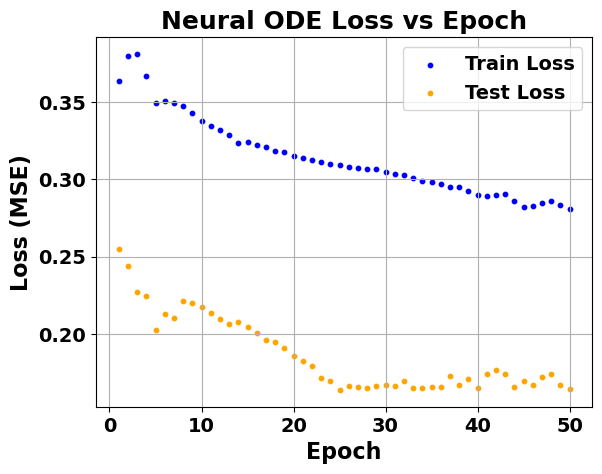

In [11]:
plt.scatter (loss_ep['epoch'], loss_ep['train_loss'], label='Train Loss', color='blue', s=10)
plt.scatter (loss_ep['epoch'], loss_ep['val_loss'], label='Test Loss', color='orange', s=10)
plt.title('Neural ODE Loss vs Epoch') 
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
#plt.yscale('log')   
plt.legend(fontsize=14)
plt.grid(True)
plt.savefig(os.path.join(loss_path, 'neural_ode_loss_vs_epoch.png'))
plt.show()


Step 4: Evaluate the model 

In [12]:
from evaluation.neural_ode.eval_neural_ode import evaluate_model
model_path = config['weight_paths']['neural_ode_model']
evaluate_model(model_path, config, device)

Metrics saved to C:/02_AtmPhy_ML/S4_AQ_PINN/evaluation/neural_ode/neural_ode_metrics.csv: 
  Parameter       MAE      RMSE        R2
0        CO  0.259282  0.376250  0.836117
1       NOx  0.263114  0.356471  0.835976
2       NO2  0.368309  0.474366  0.777988

Predictions saved to C:/02_AtmPhy_ML/S4_AQ_PINN/evaluation/neural_ode/neural_ode_predictions.csv: 
   CO_actual  NOx_actual  NO2_actual  CO_predicted  NOx_predicted  \
0   0.587902    1.442993    3.396049      0.642752       1.465387   
1   1.212887    1.768163    3.571203      1.195113       2.120972   
2   1.282330    1.680804    3.352260      1.250877       2.180651   
3   1.212887    1.525499    3.461731      1.150512       2.068114   
4   0.935116    1.506086    3.396049      0.696771       1.591946   

   NO2_predicted  
0       1.675009  
1       1.970327  
2       1.888370  
3       1.866712  
4       1.615383  


(  Parameter       MAE      RMSE        R2
 0        CO  0.259282  0.376250  0.836117
 1       NOx  0.263114  0.356471  0.835976
 2       NO2  0.368309  0.474366  0.777988,
      CO_actual  NOx_actual  NO2_actual  CO_predicted  NOx_predicted  \
 0     0.587902    1.442993    3.396049      0.642752       1.465387   
 1     1.212887    1.768163    3.571203      1.195113       2.120972   
 2     1.282330    1.680804    3.352260      1.250877       2.180651   
 3     1.212887    1.525499    3.461731      1.150512       2.068114   
 4     0.935116    1.506086    3.396049      0.696771       1.591946   
 ..         ...         ...         ...           ...            ...   
 929   0.657345    1.142089    1.819661      0.436616       0.791172   
 930   0.171245    0.564548    1.578824     -0.163652       0.103827   
 931   0.171245    0.273351    1.491247     -0.234210       0.035730   
 932  -0.037084   -0.008139    1.075256     -0.652114      -0.366351   
 933   0.032359    0.137459    1.33

Step 5: Visualize


5.1 Correlation between true and predicted values

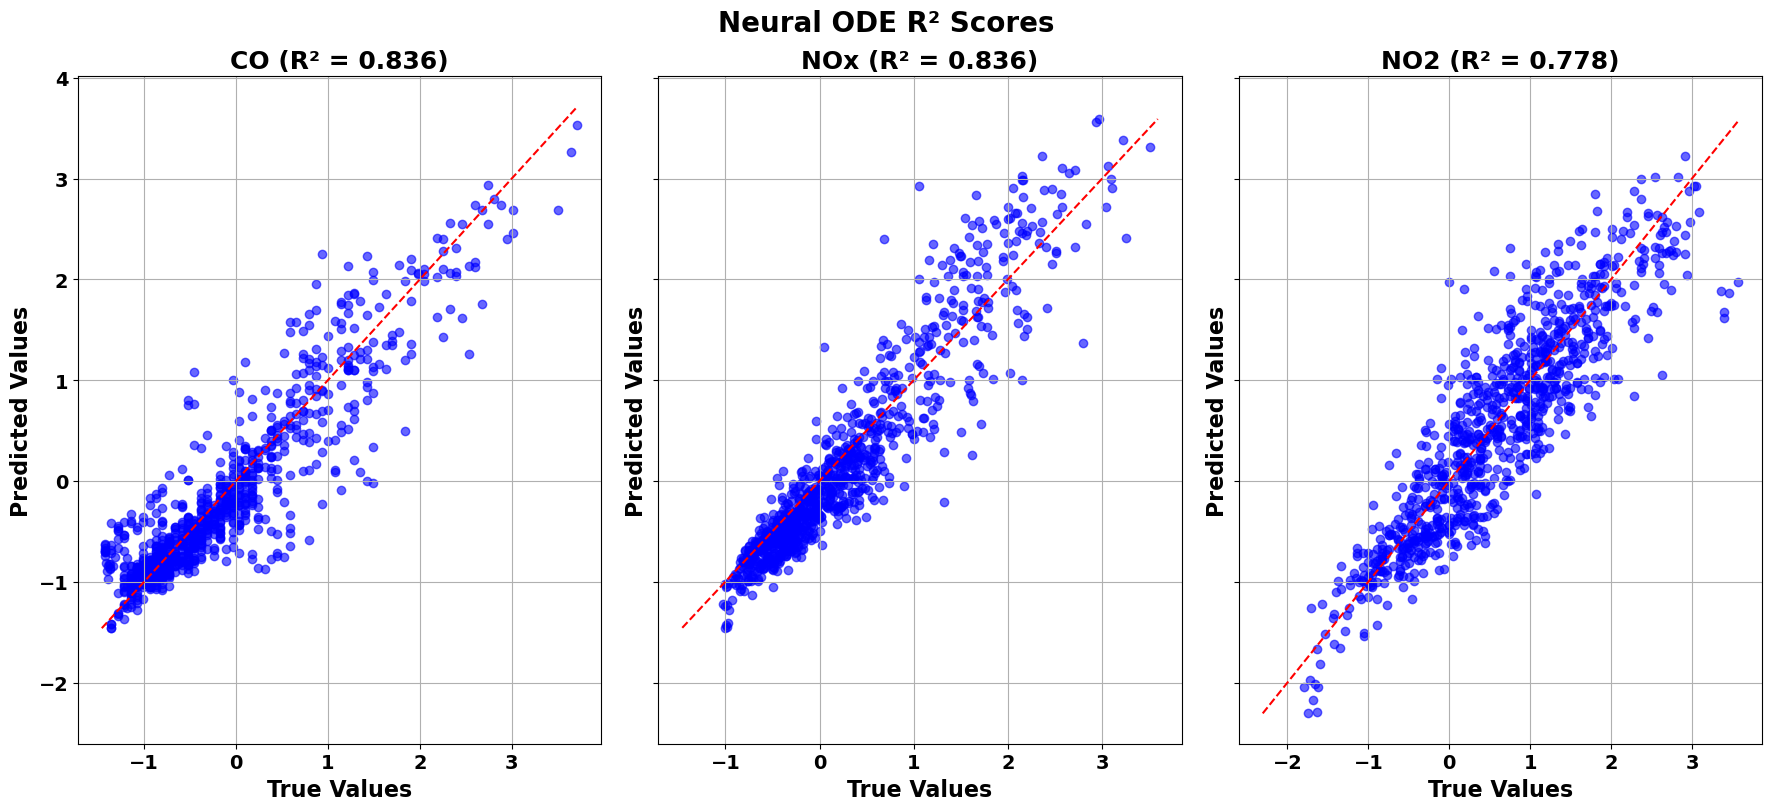

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

outpath = config['evaluation']['predictions_path']['neural_ode_predictions']
df_path = config['evaluation']['predictions_path']['neural_ode_predictions']
df = pd.read_csv(os.path.join(df_path, ('neural_ode_predictions.csv')))
true_df = df[[col for col in df.columns if 'actual' in col]]
pred_df = df[[col for col in df.columns if 'predicted' in col]]


# Assuming true_df and pred_df are pandas DataFrames containing columns like:
# true_df columns: ['CO_actual', 'NOx_actual', 'NO2_actual']
# pred_df columns: ['CO_predicted', 'NOx_predicted', 'NO2_predicted']

param_actual = ['CO_actual', 'NOx_actual', 'NO2_actual']
param_pred = ['CO_predicted', 'NOx_predicted', 'NO2_predicted']
param_names = ['CO', 'NOx', 'NO2']

fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharey=True)
for i, ax in enumerate(axes):
    true_vals = true_df[param_actual[i]]
    pred_vals = pred_df[param_pred[i]]

    ax.scatter(true_vals, pred_vals, color='blue', alpha=0.6)
    min_val = min(true_vals.min(), pred_vals.min())
    max_val = max(true_vals.max(), pred_vals.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--')  

    r2 = r2_score(true_vals, pred_vals)
    ax.set_title(f"{param_names[i]} (R² = {r2:.3f})")
    ax.set_xlabel('True Values')
    ax.set_ylabel('Predicted Values')
    ax.grid(True)

plt.tight_layout()
plt.suptitle('Neural ODE R² Scores', y=1.02)
plt.savefig(os.path.join(outpath, 'neural_ode_true_vs_pred_r2.png'))
plt.show()



5.2 Residuals and their distribution

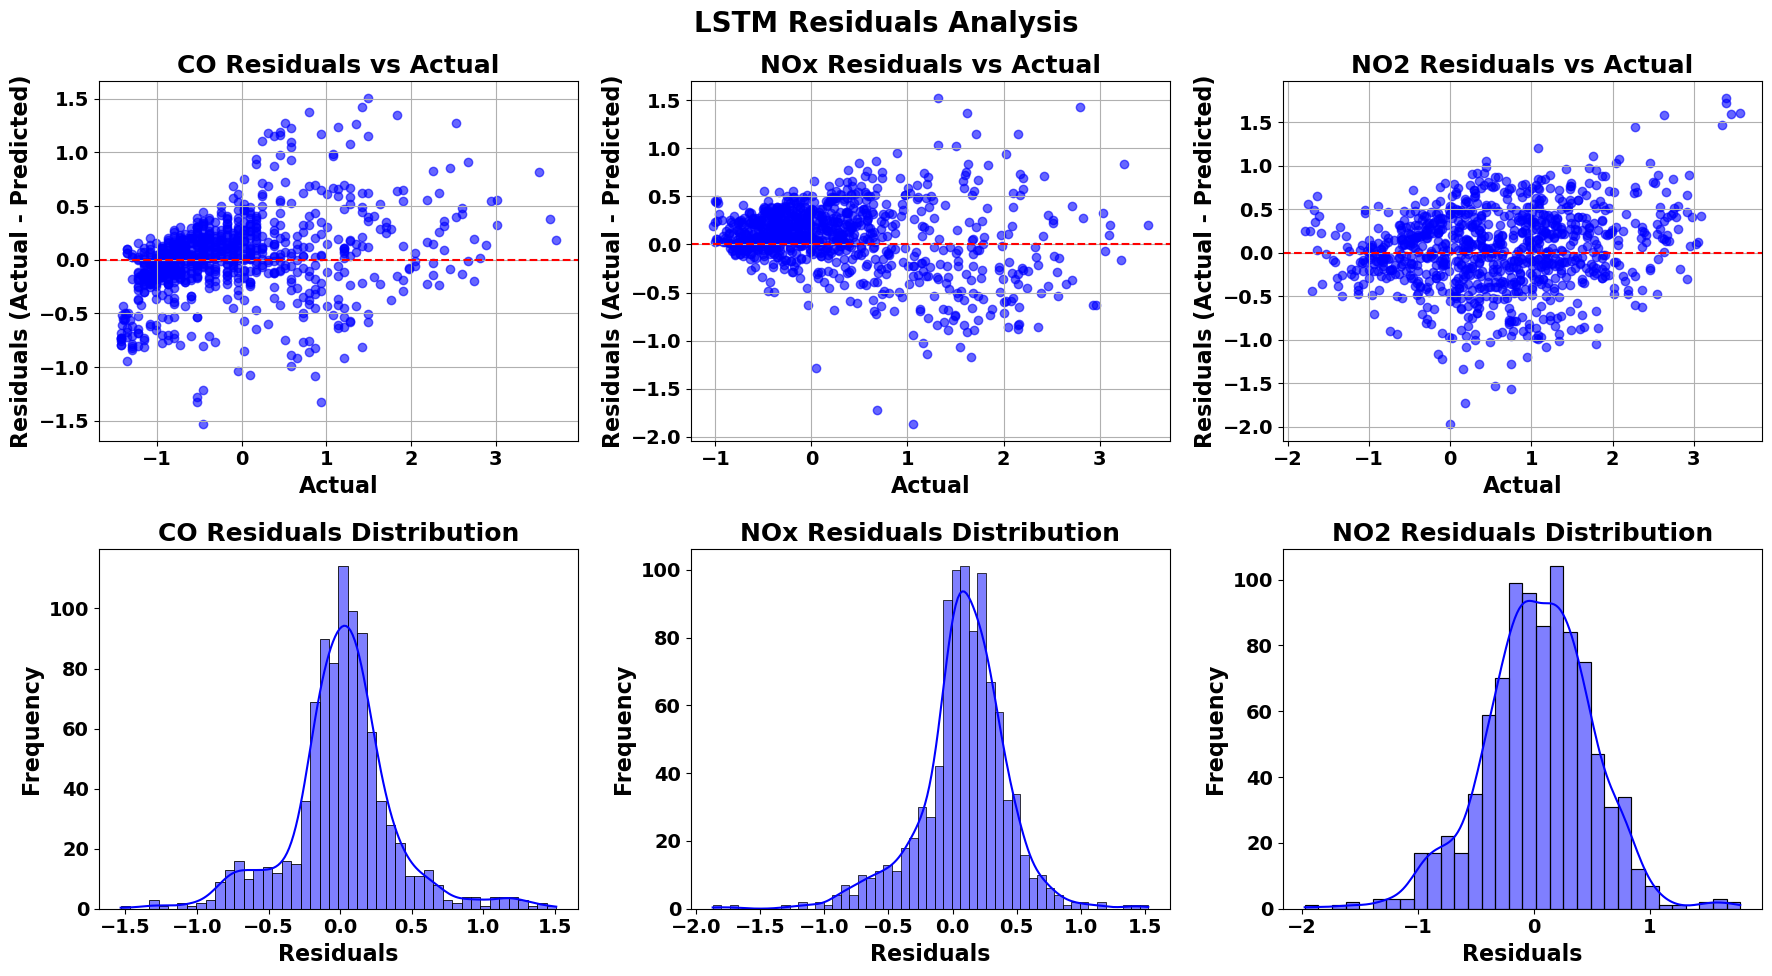

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i in range(3):
    # Residuals = actual - predicted
    residuals = true_df[param_actual[i]] - pred_df[param_pred[i]]

    # Residual plot (residuals vs actual)
    axes[0, i].scatter(true_df[param_actual[i]], residuals, color='blue', alpha=0.6)
    axes[0, i].axhline(0, color='red', linestyle='--')
    axes[0, i].set_xlabel('Actual')
    axes[0, i].set_ylabel('Residuals (Actual - Predicted)')
    axes[0, i].set_title(f'{param_names[i]} Residuals vs Actual')
    axes[0, i].grid(True)

    # Residual distribution (Histogram + KDE)
    sns.histplot(residuals, kde=True, ax=axes[1, i], color='blue')
    axes[1, i].set_xlabel('Residuals')
    axes[1, i].set_ylabel('Frequency')
    axes[1, i].set_title(f'{param_names[i]} Residuals Distribution')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.suptitle('LSTM Residuals Analysis')

plt.savefig(os.path.join(outpath, 'neural_ode_residuals_analysis.png'))
plt.show()

5.3 Temporal dynamics

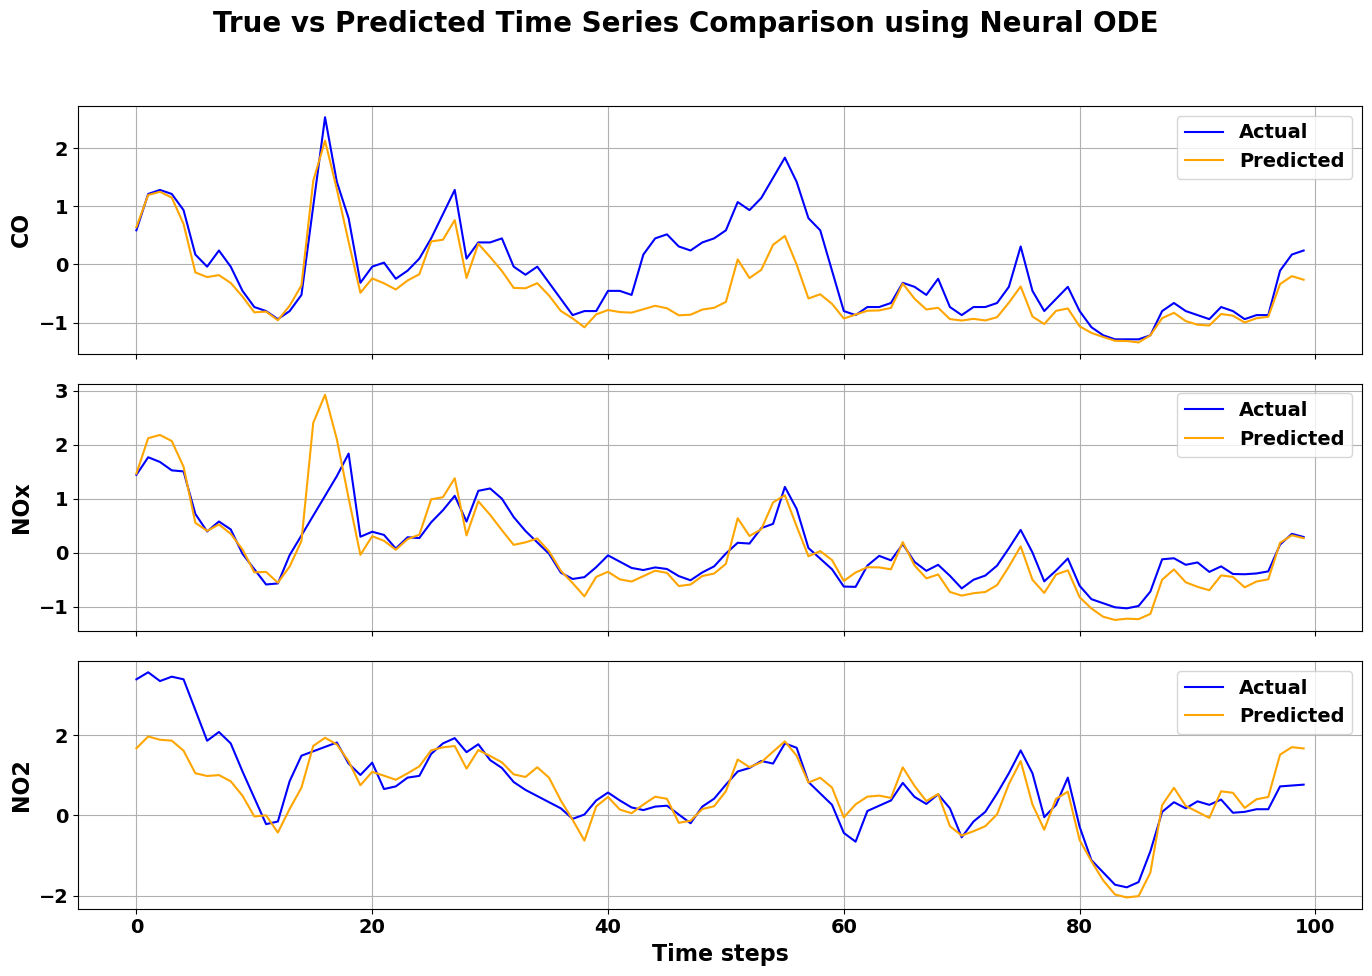

In [16]:
# Select subset time window for clarity, e.g., first 100 samples
window = 100
time_axis = range(window)  # or df['datetime'][:window] if you have timestamps

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

params = ['CO', 'NOx', 'NO2']

for i, param in enumerate(params):
    axes[i].plot(time_axis, df[f"{param}_actual"][:window], label='Actual', color='blue')
    axes[i].plot(time_axis, df[f"{param}_predicted"][:window], label='Predicted', color='orange')
    axes[i].set_ylabel(param)
    axes[i].legend()
    axes[i].grid(True)

axes[-1].set_xlabel('Time steps')

plt.suptitle('True vs Predicted Time Series Comparison using Neural ODE')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join(outpath, 'neural_ode_time_series_comparison.png'))
plt.show()

5.4 Correlation heatmap between parameters

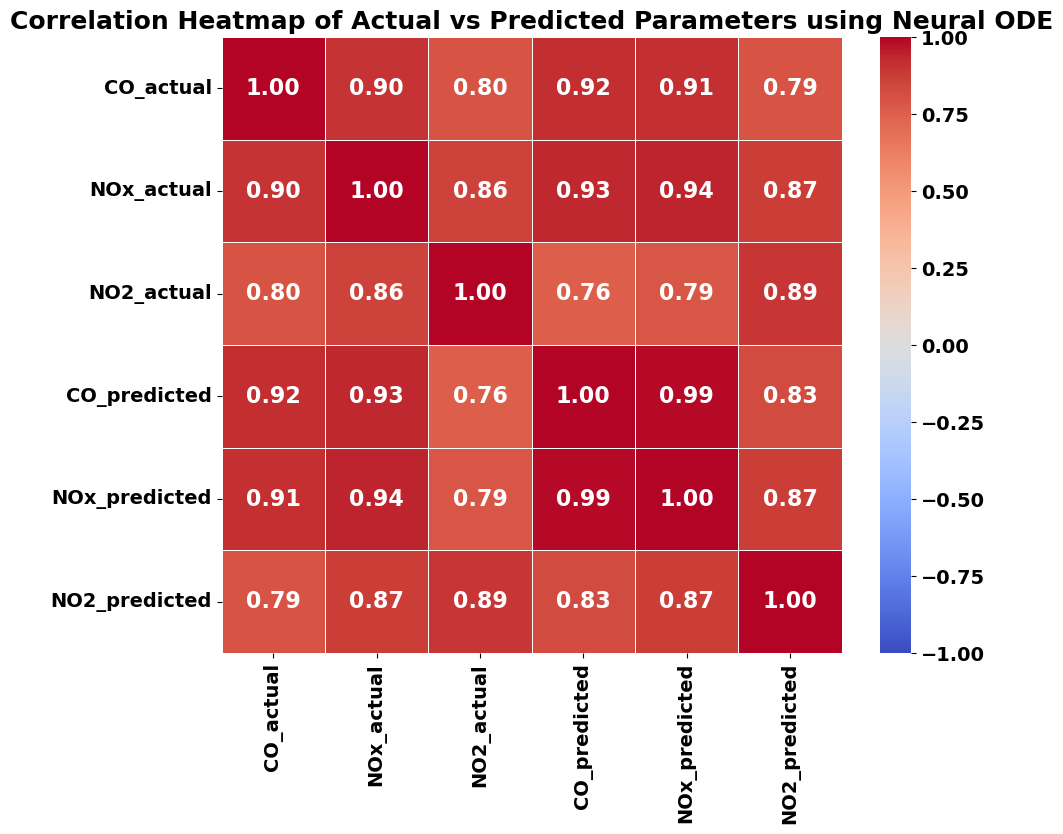

In [18]:
combined_df = df[param_actual + param_pred]

# Compute correlation matrix
corr_matrix = combined_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Actual vs Predicted Parameters using Neural ODE')
plt.savefig(os.path.join(outpath, 'neural_ode_correlation_heatmap.png'))
plt.show()